# Table of Contents
1. Introduction
2. Data Import and Exploration
3. Data Cleaning
4. AQI Category Generation
5. Duplicate and Invalid Value Checks
6. Feature Engineering
7. Exploratory Data Analysis
8. Correlation Analysis
9. Key Findings
10. Conclusion

# AIR_SHIELD:
## Predictive Air Pollution Intelligence System for India
### Objective
To analyse air quality data from Indian cities and identify pollution hotspots, seasonal patterns, yearly trends, and relationalships among pollutants.
### Dataset
-Source: Kaggle Air Quality Data in India
-File Used: city_day.csv
### Tools used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

In [1]:
import os
os.chdir("/home/shivani/projects/AIR_SHIELD")

In [2]:
import pandas as pd
df=pd.read_csv("data/raw/archive/city_day.csv")

In [3]:
import shutil
shutil.copy('data/raw/archive/city_day.csv','data/raw/raw_air_quality.csv')

'data/raw/raw_air_quality.csv'

In [4]:
print(df.shape)

(29531, 16)


In [5]:
print(df.dtypes)

City           object
Date           object
PM2.5         float64
PM10          float64
NO            float64
NO2           float64
NOx           float64
NH3           float64
CO            float64
SO2           float64
O3            float64
Benzene       float64
Toluene       float64
Xylene        float64
AQI           float64
AQI_Bucket     object
dtype: object


In [6]:
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [7]:
df.isnull().sum().sort_values(ascending=False)

Xylene        18109
PM10          11140
NH3           10328
Toluene        8041
Benzene        5623
AQI            4681
AQI_Bucket     4681
PM2.5          4598
NOx            4185
O3             4022
SO2            3854
NO2            3585
NO             3582
CO             2059
Date              0
City              0
dtype: int64

In [8]:
missing_percent=(df.isnull().sum()/len(df))*100
missing_percent.sort_values(ascending=False)

Xylene        61.322001
PM10          37.723071
NH3           34.973418
Toluene       27.229014
Benzene       19.041008
AQI           15.851139
AQI_Bucket    15.851139
PM2.5         15.570079
NOx           14.171549
O3            13.619586
SO2           13.050692
NO2           12.139785
NO            12.129626
CO             6.972334
Date           0.000000
City           0.000000
dtype: float64

# 1. Data Cleaning
Missing values, data types, and unnecessary columns are handled in this section.

In [9]:
df = df.drop(columns=['Xylene', 'Toluene', 'Benzene', 'NH3'])

In [10]:
print(df.shape)
df.isnull().sum()


(29531, 12)


City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
CO             2059
SO2            3854
O3             4022
AQI            4681
AQI_Bucket     4681
dtype: int64

In [11]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(['City', 'Date']).reset_index(drop=True)

print(df.dtypes['Date'])
df.head()

datetime64[ns]


,City,Date,PM2.5,PM10,NO,NO2,NOx,CO,SO2,O3,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,0.92,27.64,133.36,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,0.97,24.55,34.06,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,17.40,29.07,30.70,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,1.70,18.59,36.08,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,22.10,39.33,39.31,NaN,NaN


In [12]:
pollutant_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'CO', 'SO2', 'O3', 'AQI']

# Step 4a: interpolate within each city's timeline
df[pollutant_cols] = df.groupby('City')[pollutant_cols].transform(
    lambda x: x.interpolate(method='linear', limit_direction='both')
)

# Step 4b: fill any remaining gaps with that city's median
df[pollutant_cols] = df.groupby('City')[pollutant_cols].transform(
    lambda x: x.fillna(x.median())
)

df.isnull().sum()

City             0
Date             0
PM2.5            0
PM10          2009
NO               0
NO2              0
NOx           1169
CO               0
SO2              0
O3             162
AQI              0
AQI_Bucket    4681
dtype: int64

### Checking for cities with no data at all 
Before applying a global median fallback, we check whether any city has zero measurements for a specific pollutant (which interpolation and city-median can't fix).

In [13]:
df.groupby('City')['PM10'].apply(lambda x: x.isnull().all())

City
Ahmedabad             False
Aizawl                False
Amaravati             False
Amritsar              False
Bengaluru             False
Bhopal                False
Brajrajnagar          False
Chandigarh            False
Chennai               False
Coimbatore            False
Delhi                 False
Ernakulam             False
Gurugram              False
Guwahati              False
Hyderabad             False
Jaipur                False
Jorapokhar            False
Kochi                 False
Kolkata               False
Lucknow                True
Mumbai                False
Patna                 False
Shillong              False
Talcher               False
Thiruvananthapuram    False
Visakhapatnam         False
Name: PM10, dtype: bool

In [14]:
df.groupby('City')['NOx'].apply(lambda x:x.isnull().all())

City
Ahmedabad             False
Aizawl                False
Amaravati             False
Amritsar              False
Bengaluru             False
Bhopal                False
Brajrajnagar          False
Chandigarh            False
Chennai               False
Coimbatore            False
Delhi                 False
Ernakulam             False
Gurugram              False
Guwahati              False
Hyderabad             False
Jaipur                False
Jorapokhar             True
Kochi                 False
Kolkata               False
Lucknow               False
Mumbai                False
Patna                 False
Shillong              False
Talcher               False
Thiruvananthapuram    False
Visakhapatnam         False
Name: NOx, dtype: bool

In [15]:
df.groupby('City')['O3'].apply(lambda x:x.isnull().all())

City
Ahmedabad             False
Aizawl                False
Amaravati             False
Amritsar              False
Bengaluru             False
Bhopal                False
Brajrajnagar          False
Chandigarh            False
Chennai               False
Coimbatore            False
Delhi                 False
Ernakulam              True
Gurugram              False
Guwahati              False
Hyderabad             False
Jaipur                False
Jorapokhar            False
Kochi                 False
Kolkata               False
Lucknow               False
Mumbai                False
Patna                 False
Shillong              False
Talcher               False
Thiruvananthapuram    False
Visakhapatnam         False
Name: O3, dtype: bool

In [16]:
pollutant_cols=['PM2.5','PM10','NO','NO2','NOx','CO','SO2','O3','AQI']
#calculates the global median for each pollutant column and fill any remaining missing values using that global median.
df[pollutant_cols]=df[pollutant_cols].fillna(df[pollutant_cols].median())
df.isnull().sum()

City             0
Date             0
PM2.5            0
PM10             0
NO               0
NO2              0
NOx              0
CO               0
SO2              0
O3               0
AQI              0
AQI_Bucket    4681
dtype: int64

# 2. AQI Category Generation

In [17]:
def get_aqi_bucket(aqi):
    if aqi <= 50:
        return 'Good'
    elif aqi <= 100:
        return 'Satisfactory'
    elif aqi <= 200:
        return 'Moderate'
    elif aqi <= 300:
        return 'Poor'
    elif aqi <= 400:
        return 'Very Poor'
    else:
        return 'Severe'

df['AQI_Bucket'] = df['AQI'].apply(get_aqi_bucket)

df.isnull().sum()

City          0
Date          0
PM2.5         0
PM10          0
NO            0
NO2           0
NOx           0
CO            0
SO2           0
O3            0
AQI           0
AQI_Bucket    0
dtype: int64

# 3. Duplicate and Invalid Values Checks
The dataset is checked for duplicate records and invalid pollutant values.

In [18]:
# Check how many duplicate rows exist
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count}")

# Also check duplicates based on City + Date (same city, same day reported twice)
duplicate_city_date = df.duplicated(subset=['City', 'Date']).sum()
print(f"Duplicate City+Date rows: {duplicate_city_date}")

Duplicate rows: 0
Duplicate City+Date rows: 0


In [19]:
pollutant_cols=['PM2.5','PM10','NO','NO2','NOx','CO','SO2','O3','AQI']
for col in pollutant_cols:
    neg_count=(df[col]<0).sum()
    print(f"{col}:{neg_count}negative values")

PM2.5:0negative values
PM10:0negative values
NO:0negative values
NO2:0negative values
NOx:0negative values
CO:0negative values
SO2:0negative values
O3:0negative values
AQI:0negative values


# 4. Feature Engineering 
New features such as Year, Month, Day, Day of Week, and Season are extracted from the Date column.

In [20]:
df['Year']=df['Date'].dt.year
df['Month']=df['Date'].dt.month
df['Day']=df['Date'].dt.day
df['DayOfWeek']=df['Date'].dt.day_name()
df[['Date','Year','Month','Day','DayOfWeek']].head()

,Date,Year,Month,Day,DayOfWeek
0,2015-01-01,2015,1,1,Thursday
1,2015-01-02,2015,1,2,Friday
2,2015-01-03,2015,1,3,Saturday
3,2015-01-04,2015,1,4,Sunday
4,2015-01-05,2015,1,5,Monday


In [21]:
def get_season(month):
    if month in [12,1,2]:
        return 'Winter'
    elif month in[3,4,5]:
        return 'Summer'
    elif month in [6,7,8,9]:
        return 'Monsoon'
    else:
        return 'Post-Monsoon'
df['Season']=df['Month'].apply(get_season)
df[['Date','Month','Season']].head(15)

,Date,Month,Season
0,2015-01-01,1,Winter
1,2015-01-02,1,Winter
2,2015-01-03,1,Winter
3,2015-01-04,1,Winter
4,2015-01-05,1,Winter
5,2015-01-06,1,Winter
6,2015-01-07,1,Winter
7,2015-01-08,1,Winter
8,2015-01-09,1,Winter
9,2015-01-10,1,Winter


# 5. Exploratory Data Analysis (EDA)
EDA is performed to identify pollution hotspots and trends.

# Top Polluted Cities by Average PM2.5

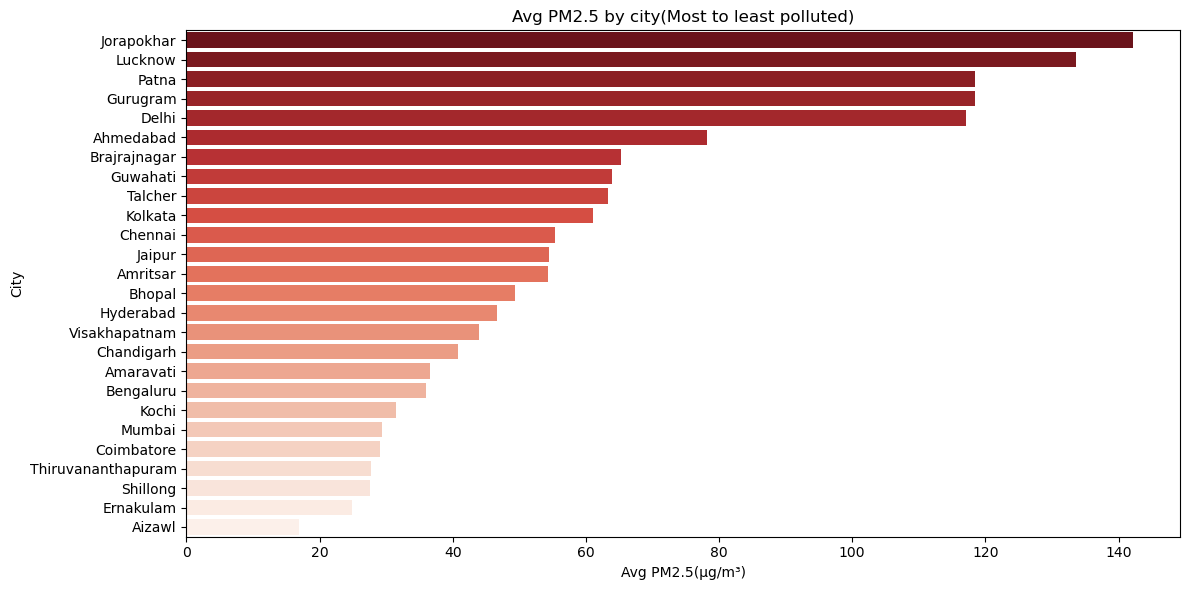

In [22]:
#first eda chart:Top polluted cities
import matplotlib.pyplot as plt
import seaborn as sns
#avg PM2.5 per city; worst to best
city_avg_pm25=df.groupby('City')['PM2.5'].mean().sort_values(ascending=False)
plt.figure(figsize=(12,6))
sns.barplot(x=city_avg_pm25.values,y=city_avg_pm25.index,hue=city_avg_pm25.index,palette='Reds_r',legend=False)
plt.xlabel('Avg PM2.5(µg/m³)')
plt.ylabel('City')
plt.title('Avg PM2.5 by city(Most to least polluted)')
plt.tight_layout()
plt.show()

# Average Pollutant Concentration Comparison

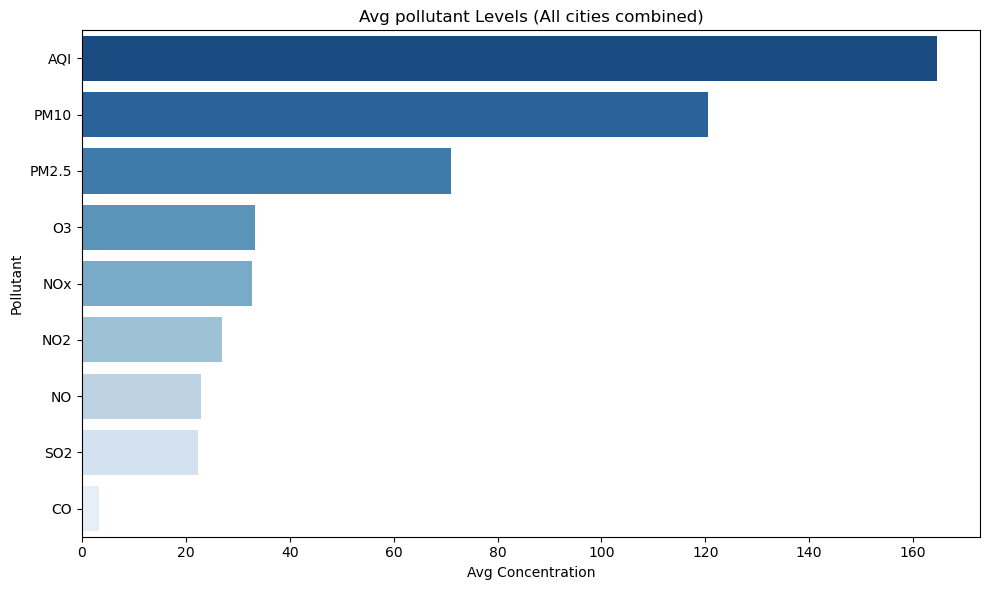

In [23]:
#pollutant comparison chart
pollutant_cols=['PM2.5','PM10','NO','NO2','NOx','CO','SO2','O3','AQI']
avg_pollutants=df[pollutant_cols].mean().sort_values(ascending=False)
plt.figure(figsize=(10,6))
sns.barplot(x=avg_pollutants.values,y=avg_pollutants.index,hue=avg_pollutants.index,palette='Blues_r',legend=False)
plt.xlabel('Avg Concentration')
plt.ylabel('Pollutant')
plt.title('Avg pollutant Levels (All cities combined)')
plt.tight_layout()
plt.show()


# Monthly PM2.5 Trend 

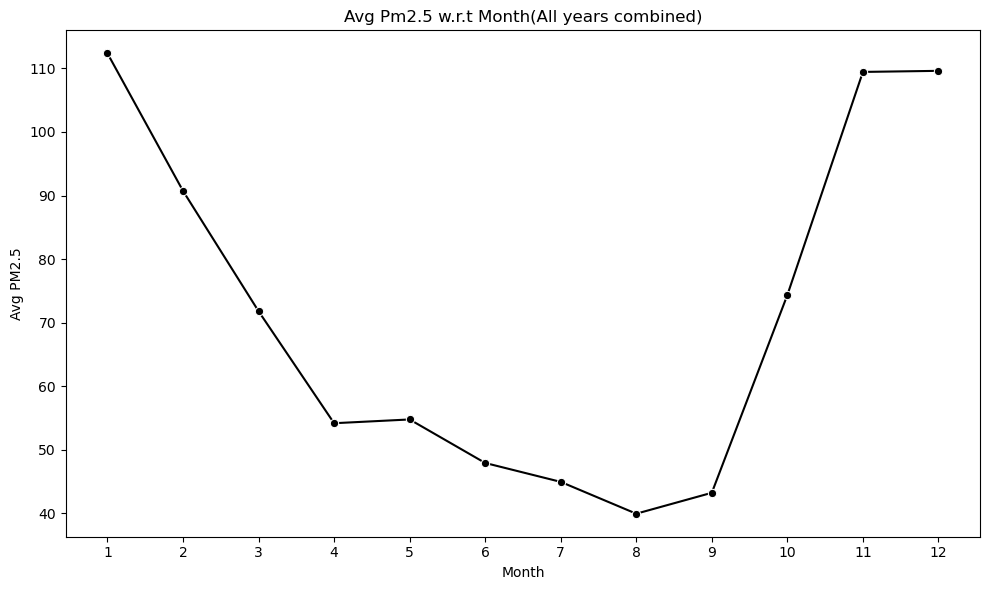

In [24]:
#Monthly trend chart
monthly_avg=df.groupby('Month')['PM2.5'].mean()
plt.figure(figsize=(10,6))
sns.lineplot(x=monthly_avg.index,y=monthly_avg.values,marker='o',color='black')
plt.xlabel('Month')
plt.ylabel('Avg PM2.5')
plt.title('Avg Pm2.5 w.r.t Month(All years combined)')
plt.xticks(range(1,13))
plt.tight_layout()
plt.show()


# Seasonal PM2.5 Trend

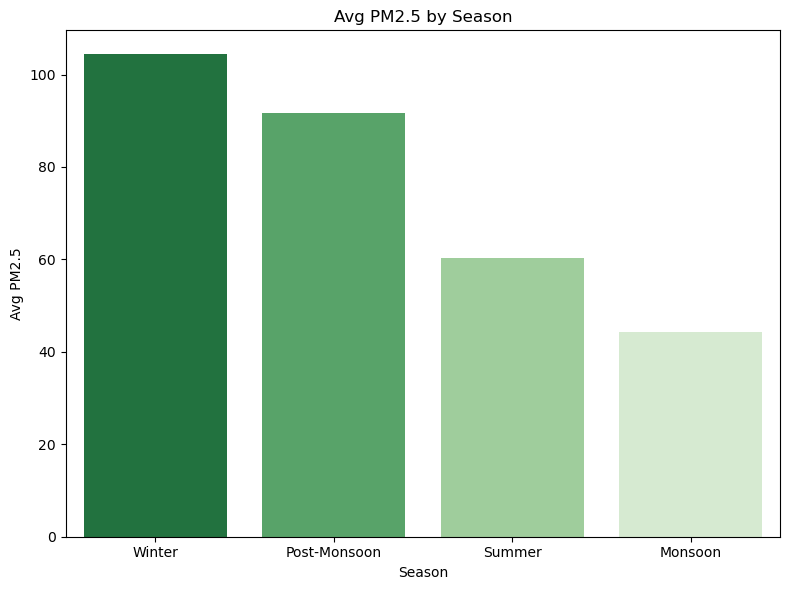

In [25]:
#seasonal trend
season_avg=df.groupby('Season')['PM2.5'].mean().sort_values(ascending=False)
plt.figure(figsize=(8,6))
sns.barplot(x=season_avg.index,y=season_avg.values,hue=season_avg.index,palette='Greens_r',legend=False)
plt.xlabel('Season')
plt.ylabel('Avg PM2.5')
plt.title('Avg PM2.5 by Season')
plt.tight_layout()
plt.show()

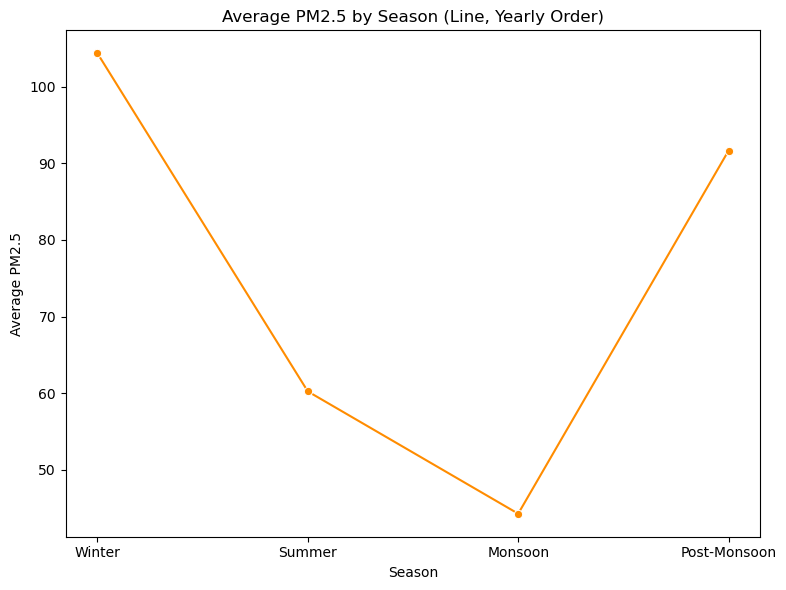

In [26]:
season_order = ['Winter', 'Summer', 'Monsoon', 'Post-Monsoon']
season_avg_ordered = df.groupby('Season')['PM2.5'].mean().reindex(season_order)

plt.figure(figsize=(8, 6))
sns.lineplot(x=season_avg_ordered.index, y=season_avg_ordered.values, marker='o', color='darkorange')
plt.xlabel('Season')
plt.ylabel('Average PM2.5')
plt.title('Average PM2.5 by Season (Line, Yearly Order)')
plt.tight_layout()
plt.show()

# Long-Term Yearly PM2.5 Trend

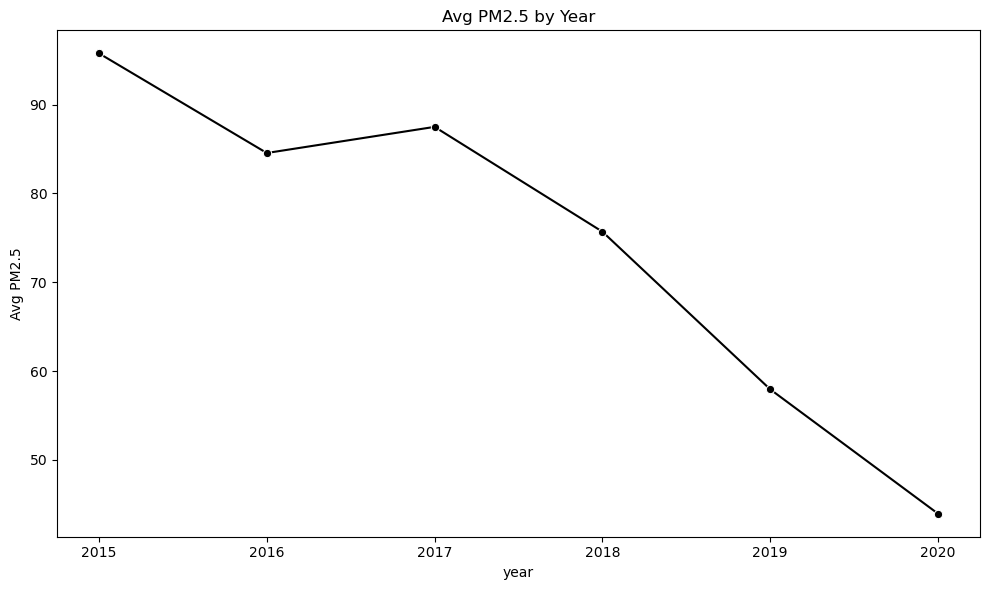

In [27]:
#Yearly trend
yearly_avg=df.groupby('Year')['PM2.5'].mean()
plt.figure(figsize=(10,6))
sns.lineplot(x=yearly_avg.index,y=yearly_avg.values,marker='o',color='black')
plt.xlabel('year')
plt.ylabel('Avg PM2.5')
plt.title('Avg PM2.5 by Year')
plt.xticks(yearly_avg.index)
plt.tight_layout()
plt.show()



# Pollutant Correlation Heatmap

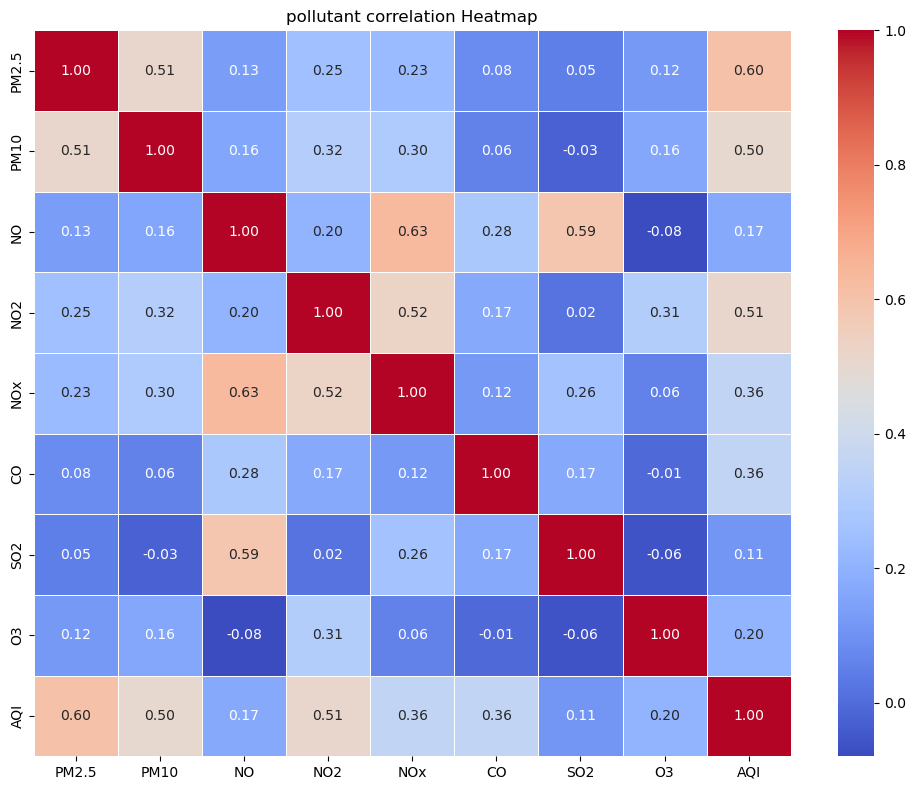

In [28]:
pollutant_cols=['PM2.5','PM10','NO','NO2','NOx','CO','SO2','O3','AQI']
corr_matrix=df[pollutant_cols].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title('pollutant correlation Heatmap')
plt.tight_layout()
plt.show()

# 6.Key Findings 
1. Pollution levels vary significantly across Indian cities.
2. PM2.5 is a major contributor to poor air quality.
3. Winter season generally records higher pollution levels.
4. Certain pollutants show strong positive correlation with AQI.
5. Long-term trends indicate changes in pollution levels over the years.

# Conclusion
The cleaned dataset and exploratory analysis provide valuable insights into air quality patterns across India and form the foundation for pollution forecasting and hotspot detection.


In [29]:
df.to_csv(
    "data/processed/cleaned_air_quality.csv",
    index=False
)

In [30]:
import os
print(os.path.exists('data/raw/raw_air_quality.csv'))
print(os.path.exists('data/processed/cleaned_air_quality.csv'))

True
True
